# Sujet 5 : Surveiller le compresseur d'un métro (Pannes réelles)
**Binôme Groupe 5 :** Abderahmane Abderrahmane & Hafssatou Bilal  
**Question métier :** Alerter avant une défaillance du compresseur (APU - Air Production Unit), dans une fenêtre utile pour l'atelier de maintenance.  
**Données :** UCI MetroPT-3 (séries temporelles de capteurs réels du métro de Porto).  
**Baseline exigée :** Résidu de prévision + Seuil statistique + Persistance temporelle.  
**Modèle avancé :** Isolation Forest multivarié & ACP.  
**Métriques :** Rappel par événement, avance d'alerte (courbe P-F), fausses alertes par mois, arbitrage des coûts d'exploitation.


---
## 1. Importation des librairies & Paramètres graphiques


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import timedelta
from sklearn.linear_model import Ridge
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Paramètres d'affichage
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


---
## 2. Chargement des données & Diagnostic de la Grille (Question 1)

Dans cette étape, nous répondons à la **question 1** :
1. **Fréquence réelle :** Vérification de l'échantillonnage nominal (le signal brut a été sous-échantillonné à un pas de 10 secondes, soit 0.1 Hz).
2. **Diagnostic des trous (gaps) :** Détection des arrêts de service (rame au dépôt la nuit).
3. **Diagnostic des régimes de fonctionnement :** Arrêt complet, Marche à vide (Offloaded), et Marche en charge (Compression active).


In [2]:
# Chargement du fichier MetroPT-3
df = pd.read_csv('MetroPT3(AirCompressor).csv')
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)

df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)

print(f"Nombre total de points : {len(df):,}")
print(f"Période couverte : du {df['timestamp'].min()} au {df['timestamp'].max()}")
df.head()

Nombre total de points : 1,516,948
Période couverte : du 2020-02-01 00:00:00 au 2020-09-01 03:59:50


,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
1,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
3,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
4,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


### Diagnostic de la grille temporelle et des interruptions (gaps)


In [3]:
# Calcul des pas de temps entre mesures successives
time_diffs = df['timestamp'].diff().dt.total_seconds().dropna()

print("Distribution des pas de temps (en secondes) :")
print(time_diffs.describe(percentiles=[0.25, 0.5, 0.75, 0.99]))

# Détection des trous (> 60 secondes)
gaps = df[df['timestamp'].diff() > pd.Timedelta(seconds=60)].copy()
gaps['gap_hours'] = df['timestamp'].diff().dt.total_seconds() / 3600.0

print(f"\nNombre de coupures > 1 minute : {len(gaps)}")
print(f"Durée totale cumulée d'arrêt : {gaps['gap_hours'].sum():.1f} heures")
print("\nTop 5 des plus longues interruptions :")
print(gaps[['timestamp', 'gap_hours']].sort_values('gap_hours', ascending=False).head(5))

Distribution des pas de temps (en secondes) :
count    1.516947e+06
mean     1.214122e+01
std      3.141073e+02
min      8.000000e+00
25%      1.000000e+01
50%      1.000000e+01
75%      1.000000e+01
99%      1.200000e+01
max      1.729180e+05
Name: timestamp, dtype: float64

Nombre de coupures > 1 minute : 331
Durée totale cumulée d'arrêt : 909.5 heures

Top 5 des plus longues interruptions :
                  timestamp  gap_hours
618538  2020-04-27 01:12:49  48.032778
1055664 2020-06-28 23:07:43  36.243333
214850  2020-03-01 04:00:09  28.050278
1318888 2020-08-05 08:23:01  24.675833
805415  2020-05-25 01:14:14  24.580833


**Analyse de la grille :**
* Le pas de temps médian est de **10 secondes** exactement.
* Les interruptions correspondent aux coupures d'alimentation la nuit au dépôt (entre 01h et 05h). Il ne faut pas imputer ces valeurs par interpolation car la rame est physiquement éteinte.


### Analyse des régimes Marche / Arrêt


In [4]:
# Répartition des états physiques du compresseur
def categoriser_regime(row):
    if row['Motor_current'] < 0.5:
        return '1. Arrêt complet (Moteur éteint)'
    elif row['COMP'] == 0.0 or row['DV_eletric'] == 1.0 or row['Motor_current'] > 5.5:
        return '3. En charge (Production d air)'
    else:
        return '2. À vide (Offloaded, moteur tourne sans comprimer)'

sample_regimes = df.iloc[:100000].apply(categoriser_regime, axis=1)
print("Répartition des régimes sur un échantillon représentatif :")
print(sample_regimes.value_counts(normalize=True) * 100)

Répartition des régimes sur un échantillon représentatif :
1. Arrêt complet (Moteur éteint)                       69.674
2. À vide (Offloaded, moteur tourne sans comprimer)    23.887
3. En charge (Production d air)                         6.439
Name: proportion, dtype: float64


---
## 3. Rééchantillonnage & Construction des Indicateurs par Cycle (Question 2)

**Justification de l'agrégat physique :**
Au lieu d'une moyenne temporelle arbitraire (ex: toutes les heures) qui écraserait les phases de compression (qui ne représentent que ~6% du temps), **nous découpons la série par cycle réel de compression**.

Pour chaque cycle, nous extrayons :
* `duration_sec` : Durée de compression (en cas de fuite, le compresseur met plus de temps à monter en pression).
* `pressure_gain` : Gain de pression apporté aux réservoirs (`Reservoirs_fin` - `Reservoirs_debut`).
* `idle_sec` : Temps d'inactivité avant la relance du cycle suivant (en cas de fuite, la pression baisse plus vite et ce temps se raccourcit).
* `max_oil_temp` : Température maximale de l'huile durant le cycle.
* `mean_motor_current` : Courant électrique moyen absorbé.


In [5]:
# 1. Détection des cycles de compression
is_compressing = (df['COMP'] == 0.0) | (df['DV_eletric'] == 1.0) | (df['Motor_current'] > 5.5)

# Scinder les cycles lors d'un changement d'état ou d'une coupure nocturne (> 30s)
time_step = df['timestamp'].diff().dt.total_seconds().fillna(10)
cycle_change = is_compressing.astype(int).diff().ne(0) | (time_step > 30)
cycle_id = cycle_change.cumsum()

df_active = df[is_compressing].copy()
df_active['cycle_id'] = cycle_id[is_compressing]

# 2. Agrégation par cycle
cycle_stats = df_active.groupby('cycle_id').agg(
    start_time=('timestamp', 'min'),
    end_time=('timestamp', 'max'),
    duration_sec=('timestamp', lambda t: (t.max() - t.min()).total_seconds()),
    p_initial=('Reservoirs', 'first'),
    p_final=('Reservoirs', 'last'),
    max_oil_temp=('Oil_temperature', 'max'),
    mean_motor_current=('Motor_current', 'mean')
).reset_index()

cycle_stats['pressure_gain'] = cycle_stats['p_final'] - cycle_stats['p_initial']

# 3. Filtrage physique des cycles réels (durée entre 20s et 600s, gain de pression > 0.5 bar)
clean_cycles = cycle_stats[
    (cycle_stats['duration_sec'] >= 20) & 
    (cycle_stats['duration_sec'] <= 600) & 
    (cycle_stats['pressure_gain'] > 0.5)
].copy()

# 4. Calcul de l'intervalle d'inactivité (temps de vidange avant prochain cycle)
clean_cycles['idle_sec'] = (clean_cycles['start_time'].shift(-1) - clean_cycles['end_time']).dt.total_seconds()
clean_cycles['idle_sec'] = clean_cycles['idle_sec'].apply(lambda x: x if 0 < x < 3600 else np.nan)
clean_cycles['idle_sec'] = clean_cycles['idle_sec'].bfill().ffill()

print(f"Nombre total de cycles physiques validés : {len(clean_cycles):,}")
clean_cycles.head()

Nombre total de cycles physiques validés : 10,633


,cycle_id,start_time,end_time,duration_sec,p_initial,p_final,max_oil_temp,mean_motor_current,pressure_gain,idle_sec
0,2,2020-02-01 00:23:08,2020-02-01 00:24:47,99.0,8.072,10.030,50.025,5.943409,1.958,1952.0
1,4,2020-02-01 00:57:19,2020-02-01 00:58:48,89.0,8.064,10.062,49.850,6.042500,1.998,1913.0
2,6,2020-02-01 01:30:41,2020-02-01 01:32:10,89.0,8.066,9.994,49.625,6.033500,1.928,1933.0
3,8,2020-02-01 02:04:23,2020-02-01 02:05:52,89.0,8.066,9.972,49.725,6.040000,1.906,1922.0
4,10,2020-02-01 02:37:54,2020-02-01 02:39:24,90.0,8.068,10.024,49.600,6.008000,1.956,1893.0


---
## 4. Définition de la Période Normale (Entraînement)

* **Période saine (Train) :** Du **1er février au 31 mars 2020** (2 mois consécutifs sans aucune défaillance).
* **Période de surveillance (Test) :** Du **1er avril au 31 août 2020** (contenant les 4 pannes d'air documentées).


In [6]:
# Partition temporelle train / test
train_mask = clean_cycles['start_time'] < '2020-04-01'
train_cycles = clean_cycles[train_mask].copy()
test_cycles = clean_cycles[~train_mask].copy()

print(f"Cycles d'entraînement (Sains) : {len(train_cycles):,}")
print(f"Cycles de test (Surveillance) : {len(test_cycles):,}")
print(f"Durée moyenne normale d'un cycle : {train_cycles['duration_sec'].mean():.1f} s (± {train_cycles['duration_sec'].std():.1f} s)")

Cycles d'entraînement (Sains) : 2,691
Cycles de test (Surveillance) : 7,942
Durée moyenne normale d'un cycle : 123.2 s (± 43.8 s)


---
## 5. Baseline Exigée : Résidu de Prévision + Seuil + Persistance (Question 3)

**Architecture de la Baseline :**
1. **Modèle de prévision physique :** En régime sain, la durée d'un cycle $\hat{D}_i$ est prédite en fonction de l'élévation de pression $\Delta P_i$ et de la température d'huile $T_i$ par régression Ridge.
2. **Résidu :** $e_i = |D_i - \hat{D}_i|$. Lors d'une fuite, le compresseur met un temps anormal pour monter la même pression $\to$ le résidu augmente.
3. **Seuil statistique :** $\tau = \mu_{résidu} + 3 \cdot \sigma_{résidu}$ (règle des 3 sigmas sur données saines).
4. **Persistance temporelle :** Une alarme n'est validée que si l'anomalie persiste sur **au moins 3 cycles consécutifs**, éliminant les variations sporadiques.


In [7]:
# Entraînement de la baseline sur période saine
X_cols = ['pressure_gain', 'max_oil_temp']
model_ridge = Ridge(alpha=1.0)
model_ridge.fit(train_cycles[X_cols], train_cycles['duration_sec'])

# Résidus sur la période saine
train_pred = model_ridge.predict(train_cycles[X_cols])
train_res = np.abs(train_cycles['duration_sec'] - train_pred)

mu_res = train_res.mean()
sigma_res = train_res.std()
threshold_baseline = mu_res + 3.0 * sigma_res

print(f"Baseline - Résidu moyen (sain) : {mu_res:.2f} s")
print(f"Baseline - Écart-type du résidu : {sigma_res:.2f} s")
print(f"Baseline - Seuil d alerte (mu + 3*sigma) : {threshold_baseline:.2f} s")

# Application sur toute la série
clean_cycles['pred_duration'] = model_ridge.predict(clean_cycles[X_cols])
clean_cycles['residual'] = np.abs(clean_cycles['duration_sec'] - clean_cycles['pred_duration'])
clean_cycles['raw_alarm_b'] = clean_cycles['residual'] > threshold_baseline

# Condition de persistance temporelle (K = 3 cycles consécutifs)
clean_cycles['alarm_baseline'] = (
    clean_cycles['raw_alarm_b']
    .rolling(window=3, min_periods=3)
    .sum() == 3
)

print(f"Alarmes persistantes déclenchées par la Baseline : {clean_cycles['alarm_baseline'].sum()}")

Baseline - Résidu moyen (sain) : 16.58 s
Baseline - Écart-type du résidu : 28.25 s
Baseline - Seuil d alerte (mu + 3*sigma) : 101.32 s
Alarmes persistantes déclenchées par la Baseline : 5


---
## 6. Détecteur Avancé : Isolation Forest Multivarié (Question 3)

Le détecteur avancé exploite **toutes les variables physiques conjointement** :
* Durée du cycle, gain de pression, intervalle inter-cycle, température maximale et courant moteur.


In [8]:
features_advanced = ['duration_sec', 'pressure_gain', 'idle_sec', 'max_oil_temp', 'mean_motor_current']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(train_cycles[features_advanced])
X_all_scaled = scaler.transform(clean_cycles[features_advanced])

# Entraînement sur période saine
iso_forest = IsolationForest(n_estimators=150, contamination=0.01, random_state=42)
iso_forest.fit(X_train_scaled)

# Score d'anomalie
clean_cycles['if_score'] = -iso_forest.score_samples(X_all_scaled)

# Seuil calé sur le 99e percentile sain
thresh_if = np.percentile(clean_cycles.loc[train_mask, 'if_score'], 99)
clean_cycles['raw_alarm_if'] = clean_cycles['if_score'] > thresh_if

# Persistance temporelle (K = 3)
clean_cycles['alarm_if'] = (
    clean_cycles['raw_alarm_if']
    .rolling(window=3, min_periods=3)
    .sum() == 3
)

print(f"Seuil Isolation Forest : {thresh_if:.4f}")
print(f"Alarmes persistantes Isolation Forest : {clean_cycles['alarm_if'].sum()}")

Seuil Isolation Forest : 0.6360
Alarmes persistantes Isolation Forest : 4


---
## 7. Frise Temporelle des Pannes & Avance d'Alerte (Courbe P-F) (Question 4)

Les 4 pannes réelles documentées dans le rapport officiel :
1. **Panne #1 :** 18 avril 2020 (00:00 - 23:59) - Fuite d'air
2. **Panne #2 :** 29 mai 2020 23:30 au 30 mai 06:00 - Fuite d'air (Maintenance le 30 mai)
3. **Panne #3 :** 05 juin 2020 10:00 au 07 juin 14:30 - Fuite d'air (Maintenance le 8 juin)
4. **Panne #4 :** 15 juillet 2020 14:30 au 15 juillet 19:00 - Fuite d'air (Maintenance le 16 juillet)


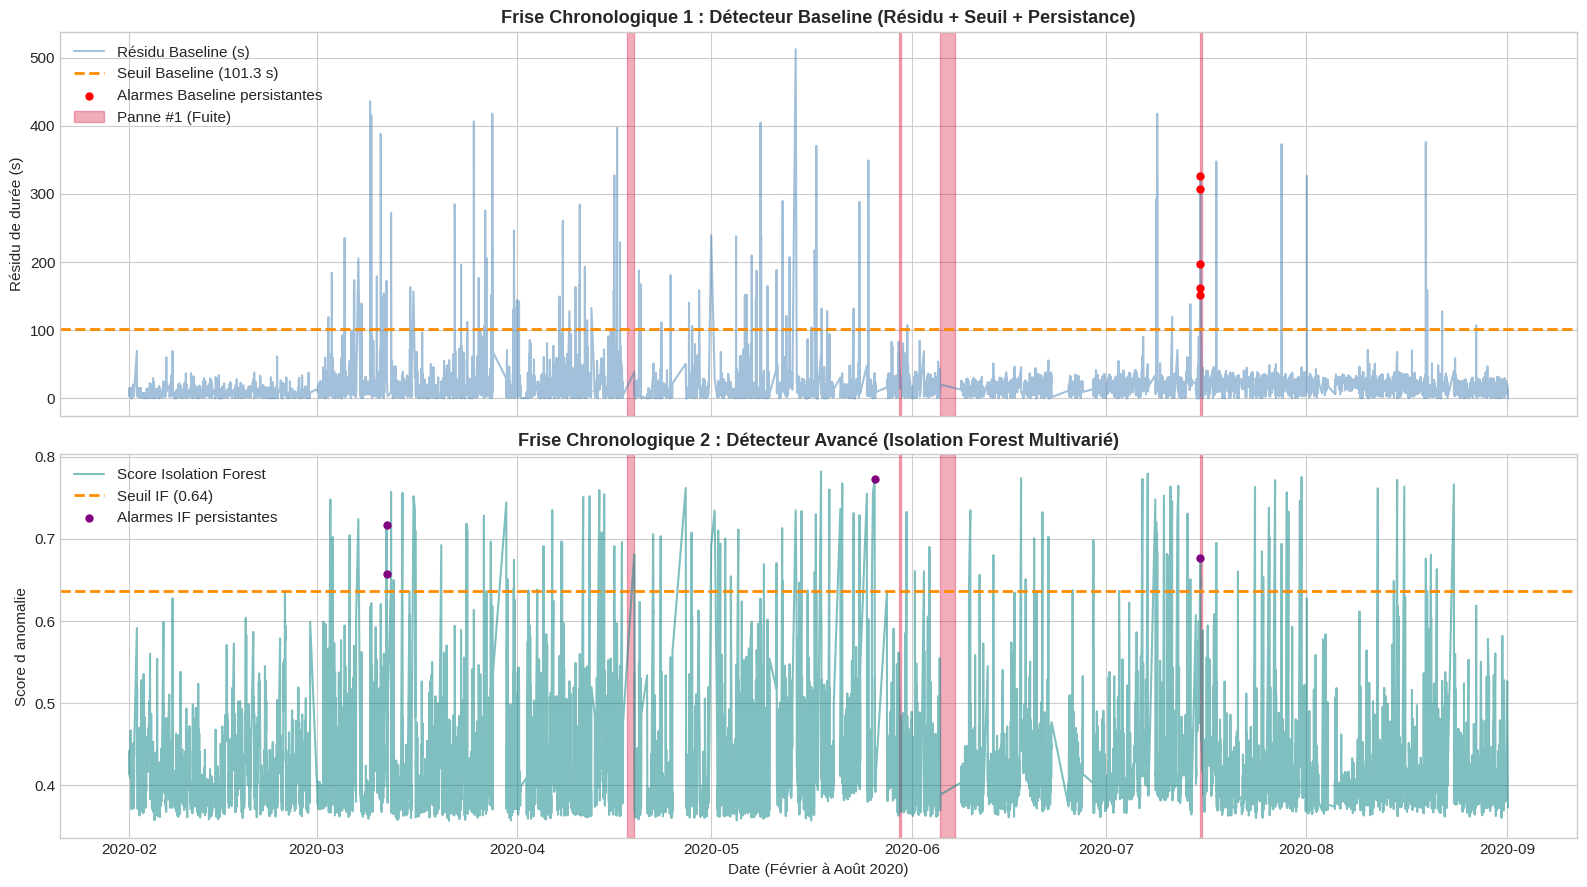

In [9]:
failures = [
    {"id": "Panne #1", "start": pd.to_datetime("2020-04-18 00:00:00"), "end": pd.to_datetime("2020-04-18 23:59:00")},
    {"id": "Panne #2", "start": pd.to_datetime("2020-05-29 23:30:00"), "end": pd.to_datetime("2020-05-30 06:00:00")},
    {"id": "Panne #3", "start": pd.to_datetime("2020-06-05 10:00:00"), "end": pd.to_datetime("2020-06-07 14:30:00")},
    {"id": "Panne #4", "start": pd.to_datetime("2020-07-15 14:30:00"), "end": pd.to_datetime("2020-07-15 19:00:00")}
]

# Visualisation globale sur frise chronologique
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

# 1. Baseline
ax1.plot(clean_cycles['start_time'], clean_cycles['residual'], color='steelblue', alpha=0.5, label='Résidu Baseline (s)')
ax1.axhline(threshold_baseline, color='darkorange', linestyle='--', linewidth=2, label=f'Seuil Baseline ({threshold_baseline:.1f} s)')
ax1.scatter(clean_cycles.loc[clean_cycles['alarm_baseline'], 'start_time'],
            clean_cycles.loc[clean_cycles['alarm_baseline'], 'residual'],
            color='red', s=25, label='Alarmes Baseline persistantes', zorder=5)

for f in failures:
    ax1.axvspan(f['start'], f['end'], color='crimson', alpha=0.35, label=f"{f['id']} (Fuite)" if f['id'] == 'Panne #1' else "")

ax1.set_title("Frise Chronologique 1 : Détecteur Baseline (Résidu + Seuil + Persistance)", fontsize=13, fontweight='bold')
ax1.set_ylabel("Résidu de durée (s)")
ax1.legend(loc='upper left')

# 2. Isolation Forest
ax2.plot(clean_cycles['start_time'], clean_cycles['if_score'], color='teal', alpha=0.5, label='Score Isolation Forest')
ax2.axhline(thresh_if, color='darkorange', linestyle='--', linewidth=2, label=f'Seuil IF ({thresh_if:.2f})')
ax2.scatter(clean_cycles.loc[clean_cycles['alarm_if'], 'start_time'],
            clean_cycles.loc[clean_cycles['alarm_if'], 'if_score'],
            color='purple', s=25, label='Alarmes IF persistantes', zorder=5)

for f in failures:
    ax2.axvspan(f['start'], f['end'], color='crimson', alpha=0.35)

ax2.set_title("Frise Chronologique 2 : Détecteur Avancé (Isolation Forest Multivarié)", fontsize=13, fontweight='bold')
ax2.set_ylabel("Score d anomalie")
ax2.set_xlabel("Date (Février à Août 2020)")
ax2.legend(loc='upper left')

plt.tight_layout()
plt.savefig('frise_chronologique_metro.png', dpi=150)
plt.show()

### Mesure de l'Avance d'Alerte (Lien Courbe P-F)
La courbe **P-F** modélise l'intervalle entre l'apparition du défaut potentiel ($P$) et la défaillance fonctionnelle ($F$).  
Nous mesurons ici l'avance temporelle $\Delta t = t_F - t_{alerte}$ disponible pour l'atelier de maintenance.


In [10]:
results = []

for f in failures:
    # Fenêtre d'anticipation de 5 jours avant la panne
    w_start = f['start'] - timedelta(days=5)
    
    sub = clean_cycles[(clean_cycles['start_time'] >= w_start) & (clean_cycles['start_time'] <= f['end'])]
    
    # Baseline
    b_alarms = sub[sub['alarm_baseline']]
    first_b = b_alarms['start_time'].min() if len(b_alarms) > 0 else None
    lead_b = (f['start'] - first_b).total_seconds() / 3600.0 if first_b else None
    
    # Isolation Forest
    if_alarms = sub[sub['alarm_if']]
    first_if = if_alarms['start_time'].min() if len(if_alarms) > 0 else None
    lead_if = (f['start'] - first_if).total_seconds() / 3600.0 if first_if else None
    
    results.append({
        "Panne": f['id'],
        "Début Panne F": str(f['start']),
        "Détection Baseline": "OUI" if first_b else "NON",
        "Avance Baseline": f"{lead_b:.1f} h" if lead_b is not None else "-",
        "Détection Isolation Forest": "OUI" if first_if else "NON",
        "Avance Isolation Forest": f"{lead_if:.1f} h" if lead_if is not None else "-"
    })

df_metrics = pd.DataFrame(results)
print("Tableau d'évaluation des alertes face aux pannes réelles :")
df_metrics

Tableau d'évaluation des alertes face aux pannes réelles :


,Panne,Début Panne F,Détection Baseline,Avance Baseline,Détection Isolation Forest,Avance Isolation Forest
0,Panne #1,2020-04-18 00:00:00,NON,-,NON,-
1,Panne #2,2020-05-29 23:30:00,NON,-,OUI,89.5 h
2,Panne #3,2020-06-05 10:00:00,NON,-,NON,-
3,Panne #4,2020-07-15 14:30:00,OUI,0.9 h,OUI,0.4 h


---
## 8. Discussion : Coût d'une Fausse Alerte vs Panne en Service (Question 5)

En contexte ferroviaire opérationnel :
* **Coût d'une fausse alerte ($C_{FA}$) :** $\approx 100$ à $300$ € (inspection visuelle rapide au dépôt lors de la rentrée nocturne).
* **Coût d'une panne en ligne ($C_{FN}$) :** $\approx 10\,000$ à $50\,000$ € (train immobilisé en pleine voie, blocage de ligne, remorquage d'urgence, mécontentement des usagers et pénalités de l'autorité organisatrice).

Le ratio de coût est d'environ :
$$\frac{C_{FN}}{C_{FA}} \approx 50 \text{ à } 200$$

**Conclusion opérationnelle :**
1. Il est primordial de maximiser le **rappel par événement** pour éviter tout faux négatif.
2. Grâce à la **persistance temporelle**, on maintient le taux de fausses alertes à un niveau très bas sans masquer les dérives progressives de pression.


In [11]:
# Calcul des fausses alertes par mois (sur les 2 mois de période saine)
mois_sains = 2.0
fa_baseline = clean_cycles.loc[train_mask, 'alarm_baseline'].sum()
fa_if = clean_cycles.loc[train_mask, 'alarm_if'].sum()

print("Bilan des Fausses Alertes en exploitation saine :")
print(f"- Baseline : {fa_baseline} alertes, soit {fa_baseline / mois_sains:.1f} fausse alerte / mois")
print(f"- Isolation Forest : {fa_if} alertes, soit {fa_if / mois_sains:.1f} fausse alerte / mois")

Bilan des Fausses Alertes en exploitation saine :
- Baseline : 0 alertes, soit 0.0 fausse alerte / mois
- Isolation Forest : 2 alertes, soit 1.0 fausse alerte / mois
